# Electricity Consumption Prediction using Multiple Linear Regression

**Activity 1 – CIE 2**  
**Student Roll Number:** AD3266

## 1. Aim
To build a Multiple Linear Regression model that predicts household appliance energy consumption using numerical temperature and humidity measurements.

## 2. Dataset
We use the **Appliances Energy Prediction** dataset from the UCI Machine Learning Repository. It contains 19,735 observations recorded at 10-minute intervals over approximately 4.5 months. The target column `Appliances` represents appliance energy use in watt-hours (Wh).

**Dataset source:** https://archive.ics.uci.edu/dataset/374/appliances-energy-prediction  
**Citation:** Candanedo, L. (2017). *Appliances Energy Prediction*. UCI Machine Learning Repository. https://doi.org/10.24432/C5VC8G

## 3. Variables
- **Input features (X):** `T1`, `RH_1`, `T2`, `RH_2`, `T_out`
- **Target (y):** `Appliances` (energy use in Wh)

The selected inputs are numerical temperature and humidity measurements. This is a regression task because the target is a numerical quantity.


## 4. Import required libraries

In [1]:
!pip -q install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline

## 5. Load the dataset

In [2]:
# Fetch dataset directly from the UCI Machine Learning Repository
dataset = fetch_ucirepo(id=374)

X_all = dataset.data.features
y_all = dataset.data.targets

print("Feature columns:")
print(X_all.columns.tolist())
print("\nTarget columns:")
print(y_all.columns.tolist())

df = X_all.join(y_all)
df.head()

Feature columns:
['date', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']

Target columns:
['Appliances']


,date,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Appliances
0,2016-01-1117:00:00,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,60
1,2016-01-1117:10:00,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,60
2,2016-01-1117:20:00,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,50
3,2016-01-1117:30:00,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,45.410390,45.410390,50
4,2016-01-1117:40:00,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,60


## 6. Select features and target

In [13]:

# Select input features and target

feature_columns = [
    "lights",
    "T1", "RH_1",
    "T2", "RH_2",
    "T3", "RH_3",
    "T4", "RH_4",
    "T5", "RH_5",
    "T6", "RH_6",
    "T7", "RH_7",
    "T8", "RH_8",
    "T9", "RH_9",
    "T_out",
    "Press_mm_hg",
    "RH_out",
    "Windspeed",
    "Visibility",
    "Tdewpoint"
]

target_column = "Appliances"

data = df[feature_columns + [target_column]].copy()

print("Dataset shape:", data.shape)
print("\nFirst five rows:")
display(data.head())

print("\nMissing values:")
print(data.isnull().sum())


Dataset shape: (19735, 26)

First five rows:


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,Appliances
0,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,...,48.900000,17.033333,45.53,6.60,733.5,92.0,7.000000,63.000000,5.3,60
1,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,...,48.863333,17.066667,45.56,6.48,733.6,92.0,6.666667,59.166667,5.2,60
2,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,...,48.730000,17.000000,45.50,6.37,733.7,92.0,6.333333,55.333333,5.1,50
3,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,...,48.590000,17.000000,45.40,6.25,733.8,92.0,6.000000,51.500000,5.0,50
4,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,...,48.590000,17.000000,45.40,6.13,733.9,92.0,5.666667,47.666667,4.9,60



Missing values:
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
Appliances     0
dtype: int64


## 7. Exploratory Data Analysis

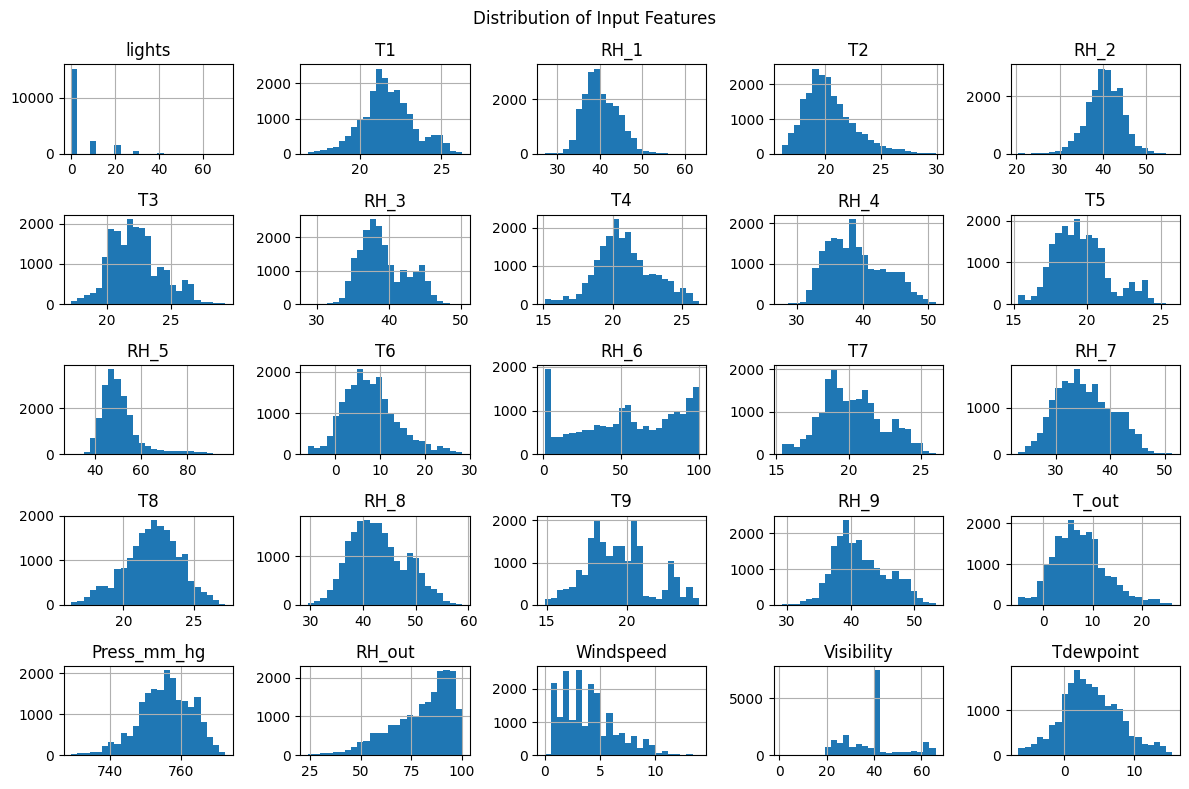

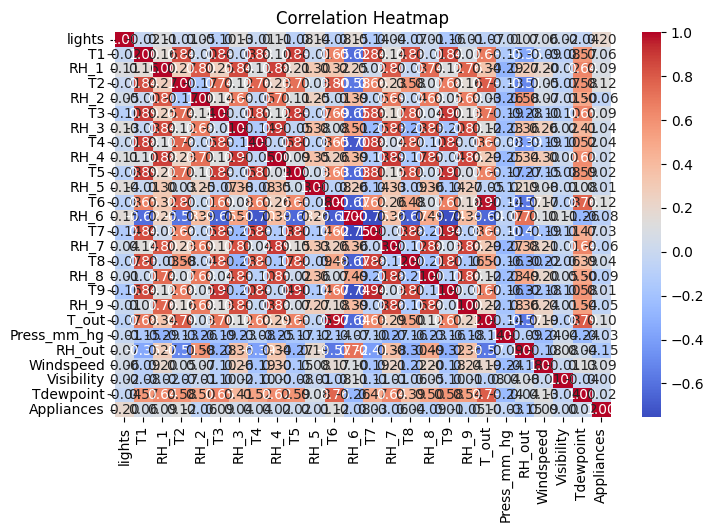

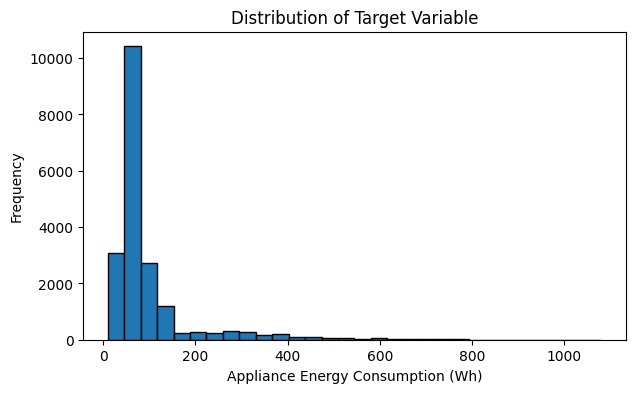

In [14]:
data[feature_columns].hist(figsize=(12, 8), bins=25)
plt.suptitle("Distribution of Input Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(data[target_column], bins=30, edgecolor="black")
plt.xlabel("Appliance Energy Consumption (Wh)")
plt.ylabel("Frequency")
plt.title("Distribution of Target Variable")
plt.show()

## 8. Prepare data and split into training and testing sets

In [15]:
X = data[feature_columns]
y = data[target_column]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 15788
Testing samples: 3947


## 9. Train the Multiple Linear Regression model

In [16]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


## 10. Make predictions

In [17]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Consumption (Wh)": y_test.values,
    "Predicted Consumption (Wh)": y_pred
})
display(results.head(10))

,Actual Consumption (Wh),Predicted Consumption (Wh)
0,40,43.146494
1,90,259.046599
2,50,46.917678
3,50,116.247267
4,70,33.166090
5,120,193.174922
6,120,90.329721
7,70,176.082023
8,50,85.045558
9,70,146.218445


## 11. Evaluate model performance

In [18]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f} Wh")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} Wh")
print(f"R-squared (R²): {r2:.4f}")

Mean Absolute Error (MAE): 52.54 Wh
Mean Squared Error (MSE): 8312.20
Root Mean Squared Error (RMSE): 91.17 Wh
R-squared (R²): 0.1694


## 12. Display the regression equation

In [19]:
print(f"Intercept: {model.intercept_:.4f}")
print("\nCoefficients:")
for feature, coefficient in zip(feature_columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

equation = f"Appliances = {model.intercept_:.3f}"
for feature, coefficient in zip(feature_columns, model.coef_):
    equation += f" + ({coefficient:.3f} × {feature})"

print("\nEstimated regression equation:")
print(equation)

Intercept: 22.9941

Coefficients:
lights: 1.9300
T1: 0.0772
RH_1: 15.9057
T2: -17.5966
RH_2: -13.6177
T3: 25.8680
RH_3: 4.4859
T4: -3.8803
RH_4: -0.4073
T5: -0.8683
RH_5: 0.2125
T6: 7.3837
RH_6: 0.3409
T7: 2.2436
RH_7: -1.6630
T8: 7.4487
RH_8: -4.5607
T9: -15.1687
RH_9: -1.0305
T_out: -10.4830
Press_mm_hg: 0.1621
RH_out: -1.0695
Windspeed: 1.7784
Visibility: 0.1617
Tdewpoint: 4.9929

Estimated regression equation:
Appliances = 22.994 + (1.930 × lights) + (0.077 × T1) + (15.906 × RH_1) + (-17.597 × T2) + (-13.618 × RH_2) + (25.868 × T3) + (4.486 × RH_3) + (-3.880 × T4) + (-0.407 × RH_4) + (-0.868 × T5) + (0.213 × RH_5) + (7.384 × T6) + (0.341 × RH_6) + (2.244 × T7) + (-1.663 × RH_7) + (7.449 × T8) + (-4.561 × RH_8) + (-15.169 × T9) + (-1.031 × RH_9) + (-10.483 × T_out) + (0.162 × Press_mm_hg) + (-1.069 × RH_out) + (1.778 × Windspeed) + (0.162 × Visibility) + (4.993 × Tdewpoint)


## 13. Actual vs Predicted plot

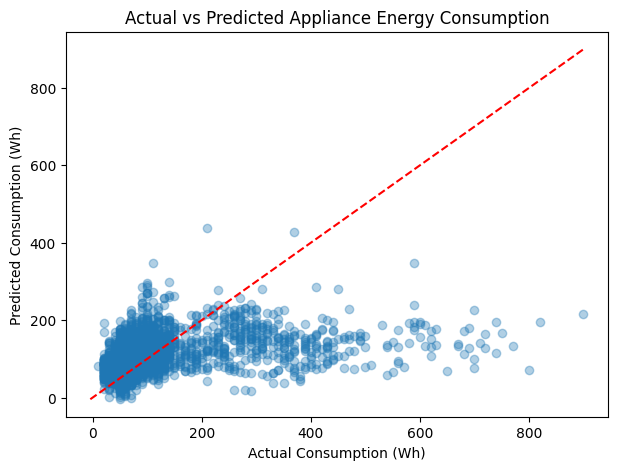

In [20]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.35)
line_min = min(y_test.min(), y_pred.min())
line_max = max(y_test.max(), y_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], "r--")
plt.xlabel("Actual Consumption (Wh)")
plt.ylabel("Predicted Consumption (Wh)")
plt.title("Actual vs Predicted Appliance Energy Consumption")
plt.show()

## 14. Residual plot

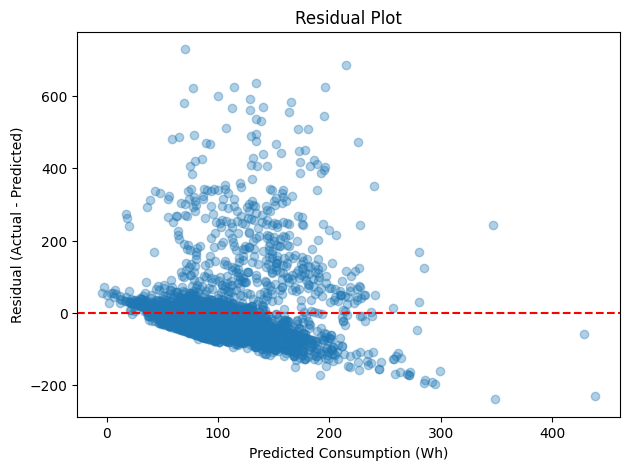

In [21]:
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.35)
plt.axhline(y=0, color="red", linestyle="--")
plt.xlabel("Predicted Consumption (Wh)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

## 15. Predict consumption for a new example

In [24]:

# Predict consumption for a new example

# Start with the median values of all 23 training features
new_house_conditions = pd.DataFrame(
    [X_train.median().to_dict()],
    columns=feature_columns
)

# Change a few values for our example
new_house_conditions["T1"] = 21.0
new_house_conditions["RH_1"] = 40.0
new_house_conditions["T2"] = 20.0
new_house_conditions["RH_2"] = 40.0
new_house_conditions["T_out"] = 10.0

# Display input values
display(new_house_conditions)

# Predict energy consumption
predicted_consumption = model.predict(new_house_conditions)[0]

print(
    f"Predicted appliance energy consumption: "
    f"{predicted_consumption:.2f} Wh"
)


,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint
0,0.0,21.0,40.0,20.0,40.0,22.1,38.56,20.633333,38.463333,19.39,...,22.1,42.427857,19.39,40.933333,10.0,756.1,84.0,3.666667,40.0,3.43


Predicted appliance energy consumption: 59.28 Wh


## 16. Conclusion

In this activity, a Multiple Linear Regression model was developed to estimate appliance energy consumption using five numerical temperature and humidity features. The model was evaluated using MAE, MSE, RMSE, and R², and its predictions were visualized using actual-versus-predicted and residual plots.

